# Листок № 1. СЛАУ, матрицы, квадратичные формы
Условия взяты из `Практические занятия Листок 1.pdf`. Если в листке есть ответ, вычисление сверяется с ним через `assert`.

In [1]:
%matplotlib inline
import itertools
from math import comb
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import sympy as sp
from sympy import Matrix, Rational, symbols, sqrt
from IPython.display import display
sp.init_printing()

**1.1.** Найти общее решение системы
$$x_1+5x_2-2x_3=-7,\quad -3x_1+x_2+9x_3-5x_4=9,\quad 4x_1-8x_2-x_3+7x_4=0.$$

In [2]:
A_b = Matrix([[1,5,-2,0,-7],[-3,1,9,-5,9],[4,-8,-1,7,0]])
R, piv = A_b.rref()
display(R, piv)
x1,x2,x3,x4 = symbols('x1:5')
display(sp.linsolve(A_b, x1,x2,x3,x4))
assert R == Matrix([[1,0,0,Rational(8,7),Rational(-11,7)],[0,1,0,Rational(-2,7),Rational(-6,7)],[0,0,1,Rational(-1,7),Rational(4,7)]])

⎡1  0  0  8/7   -11/7⎤
⎢                    ⎥
⎢0  1  0  -2/7  -6/7 ⎥
⎢                    ⎥
⎣0  0  1  -1/7   4/7 ⎦

**Ответ:** $x_4$ — свободная переменная, $x=\left(-\tfrac{11}{7}-\tfrac87x_4;\ -\tfrac67+\tfrac27x_4;\ \tfrac47+\tfrac17x_4;\ x_4\right)$. Совпадает с rref из листка.

**1.2.** Найти rref расширенной матрицы и общее решение системы
$$5x_1-x_2+5x_3+9x_4-2x_5=-3,\quad 3x_1+6x_3+9x_4-x_5=4,\quad 2x_1+4x_3+6x_4-x_5=0.$$

In [3]:
A_b = Matrix([[5,-1,5,9,-2,-3],[3,0,6,9,-1,4],[2,0,4,6,-1,0]])
R, piv = A_b.rref()
display(R)
xs = symbols('x1:6')
display(sp.linsolve(A_b, *xs))
assert R == Matrix([[1,0,2,3,0,4],[0,1,5,6,0,7],[0,0,0,0,1,8]])

⎡1  0  2  3  0  4⎤
⎢                ⎥
⎢0  1  5  6  0  7⎥
⎢                ⎥
⎣0  0  0  0  1  8⎦

**Ответ:** $x=(4-2x_3-3x_4;\ 7-5x_3-6x_4;\ x_3;\ x_4;\ 8)$. Совпадает с ответом листка.

**1.3.** Пусть $(x,y,z,u)$ — решение системы
$$32x+97y+90z+48u=47,\quad 35x+84y+91z+54u=40,\quad 17x+18y+21z+13u=37.$$
Почему $y=a+bx$? Найти $a$ и $b$.

**Объяснение.** Перенесём слагаемые с $x$ вправо: получим систему $3\times3$ относительно $(y,z,u)$ с матрицей $B$. Если $\det B\ne0$, то по формулам Крамера $y$ равно отношению определителей, а столбец правых частей линейно зависит от $x$. Значит, $y$ — линейная функция от $x$, и её коэффициенты зависят только от коэффициентов системы.

In [4]:
x,y,z,u = symbols('x y z u')
eqs = [32*x+97*y+90*z+48*u-47, 35*x+84*y+91*z+54*u-40, 17*x+18*y+21*z+13*u-37]
B = Matrix([[97,90,48],[84,91,54],[18,21,13]])
print('det B =', B.det())
sol = sp.solve(eqs,(y,z,u))
display(sp.Eq(y, sol[y]))
a, b = sol[y].subs(x,0), sol[y].coeff(x)
print('a =',a,' b =',b)
assert (a,b)==(14027,-4262)

det B = 1


a = 14027  b = -4262


**Ответ:** $a=14027$, $b=-4262$ (совпадает с листком).

**1.4.** Выполнить действия с матрицами из листка.

In [5]:
A = Matrix([[3,0,2],[0,1,3],[2,2,0],[0,1,0]])
B = Matrix([[1,2,-1,2],[-2,-1,1,2],[2,1,1,2]])
C = Matrix([[0,-4,6,1],[2,2,-5,-2],[2,-2,6,4],[1,3,0,1]])
display(A*B+C)

⎡7   4  5   11⎤
⎢             ⎥
⎢6   4  -1  6 ⎥
⎢             ⎥
⎢0   0  6   12⎥
⎢             ⎥
⎣-1  2  1   3 ⎦

**1.5.** Найти определители порядка $n$: а) $a_{ij}=\min(i,j)$; б) $a_{ij}=\max(i,j)$; в)* $a_{ij}=|i-j|$.

Во всех трёх случаях из каждой строки, начиная с последней, вычитаем предыдущую.

**а)** Строка $i\geqslant2$ становится равной $(0,\dots,0,1,\dots,1)$ с первой единицей на месте $i$, первая строка состоит из единиц. Матрица верхнетреугольная с единицами на диагонали, поэтому $\det=1$.

**б)** Строка $i\geqslant2$ становится равной $(1,\dots,1,0,\dots,0)$ с $i-1$ единицами, первая строка равна $(1,2,\dots,n)$. В последнем столбце ненулевой только элемент $n$ в первой строке. Минор при нём нижнетреугольный с единицами на диагонали, поэтому $\det=(-1)^{n+1}n$.

**в)** Строка $i\geqslant2$ становится равной $(1,\dots,1,-1,\dots,-1)$ с $i-1$ единицами, первая строка равна $(0,1,\dots,n-1)$. Прибавим первый столбец ко всем остальным: первая строка не изменится, а строка $i\geqslant2$ примет вид $(1,2,\dots,2,0,\dots,0)$, где нули стоят в столбцах $j\geqslant i$. В последнем столбце ненулевой только элемент $n-1$ в первой строке. Минор при нём нижнетреугольный с диагональю $(1,2,\dots,2)$ и равен $2^{n-2}$. Поэтому $\det=(-1)^{n+1}(n-1)2^{n-2}$.

Формулы проверяются точным вычислением:

In [6]:
for k in range(2,10):
    a = Matrix(k,k,lambda i,j:min(i,j)+1).det()
    b = Matrix(k,k,lambda i,j:max(i,j)+1).det()
    c = Matrix(k,k,lambda i,j:abs(i-j)).det()
    assert a==1 and b==(-1)**(k-1)*k and c==(-1)**(k-1)*(k-1)*2**(k-2)
    print(f'n={k}: min {a}, max {b}, |i-j| {c}')

n=2: min 1, max -2, |i-j| -1
n=3: min 1, max 3, |i-j| 4
n=4: min 1, max -4, |i-j| -12
n=5: min 1, max 5, |i-j| 32
n=6: min 1, max -6, |i-j| -80
n=7: min 1, max 7, |i-j| 192
n=8: min 1, max -8, |i-j| -448
n=9: min 1, max 9, |i-j| 1024


**Ответ:** а) $1$; б) $(-1)^{n-1}n$; в) $(-1)^{n-1}(n-1)2^{n-2}$.

**1.6.**\*\* Найти наибольшее значение определителя 6-го порядка из чисел $-1,0,1$.

**Сведение перебора.**
1. Определитель линеен по каждому элементу, поэтому максимум на кубе $[-1,1]^{36}$ достигается в вершине. Нули не нужны, достаточно матриц из $\pm1$.
2. Умножая строки и столбцы на $-1$, делаем первую строку и первый столбец единичными (модуль $\det$ не меняется).
3. Вычтем первую строку из остальных: остаётся блок $5\times5$ из чисел $0,-2$, так что $|\det|=2^5|\det M|$, где $M$ — матрица $5\times5$ из $0,1$.
4. Перестановка строк не меняет $|\det M|$, а при совпадающих строках $\det M=0$. Достаточно перебрать наборы из пяти различных строк: $\binom{32}{5}=201376$ вариантов.

In [7]:
rows = np.array(list(itertools.product([0,1],repeat=5)),float)
idx = np.array(list(itertools.combinations(range(32),5)))
dets = np.abs(np.linalg.det(rows[idx]))
best = int(round(dets.max()))
print('перебрано', len(idx), ' max|det M| =', best, ' ответ =', 32*best)
M = rows[idx[dets.argmax()]].astype(int)
# Восстанавливаем явную матрицу 6x6 из ±1 и проверяем точным вычислением
H = sp.ones(6,6)
for i in range(5):
    for j in range(5):
        H[i+1,j+1] = 1-2*int(M[i,j])
if H.det()<0:
    H[1,:] = -H[1,:]
display(H); print('det =', H.det())
assert H.det()==160

перебрано

 201376  max|det M| = 5  ответ = 160


⎡1   1   1   1   1   1 ⎤
⎢                      ⎥
⎢-1  -1  -1  -1  1   1 ⎥
⎢                      ⎥
⎢1   1   1   -1  1   -1⎥
⎢                      ⎥
⎢1   1   -1  -1  -1  1 ⎥
⎢                      ⎥
⎢1   -1  1   -1  -1  1 ⎥
⎢                      ⎥
⎣1   -1  -1  1   1   -1⎦

det = 160


**Ответ:** $160$.

**1.7.** $n=80000$; диагональ — арифметическая прогрессия от $0{,}99$ до $1{,}01$; вне диагонали только $a_{1,2}=0{,}57$, $a_{2,1}=0{,}03$. Найти $\det A$ и $\operatorname{tr}A^{-1}$.

Матрица блочно-диагональная: блок $2\times2$ и диагональ. Определитель равен произведению определителей блоков, след обратной — сумме следов. Произведение считаем через сумму логарифмов.

In [8]:
n_ = 80000
d = np.linspace(0.99,1.01,n_)
block = np.array([[d[0],0.57],[0.03,d[1]]])
det_A = np.linalg.det(block)*np.exp(np.log(d[2:]).sum())
tr = np.trace(np.linalg.inv(block))+(1/d[2:]).sum()
print(f'det A = {det_A:.3f}, tr A^-1 = {tr:.3f}')
assert round(det_A,3)==0.259 and round(tr,3)==80002.703

det A = 0.259, tr A^-1 = 80002.703


**Ответ:** $0{,}259$; $80002{,}703$ (совпадает с листком).

**1.8.** $n=43000$; диагональ — геометрическая прогрессия от $1$ до $1{,}07$; первая строка — арифметическая прогрессия с $a_{1,n}=1{,}10$; остальное — нули. Найти $B=A^{-1}$: наименьший элемент и сумму элементов.

Первая строка начинается с $a_{1,1}=1$. Проверкой $AB=I$ получаем: $b_{ii}=1/a_{ii}$, $b_{1j}=-a_{1j}/a_{jj}$ при $j>1$, остальные элементы равны нулю.

In [9]:
n_ = 43000
q = 1.07**(1/(n_-1))
dg = q**np.arange(n_)
r1 = np.linspace(1,1.10,n_)
off = -r1[1:]/dg[1:]
mn = min(off.min(),(1/dg).min())
s = (1/dg).sum()+off.sum()
print(f'min B = {mn:.3f}, сумма = {s:.1f}')
# Проверка формулы обратной матрицы на малом n
m=7; qq=1.07**(1/(m-1)); D=qq**np.arange(m); R=np.linspace(1,1.1,m)
Am=np.diag(D); Am[0,:]=R
Bm=np.diag(1/D); Bm[0,1:]=-R[1:]/D[1:]
assert np.allclose(Am@Bm,np.eye(m))
assert round(mn,3)==-1.028 and round(s,1)==-2054.4

min B = -1.028, сумма = -2054.4


**Ответ:** $-1{,}028$; $-2054{,}4$ (совпадает с листком).

**1.9.** $A=\gamma\begin{pmatrix}7&14\\9&1\end{pmatrix}$, $\gamma=0{,}057$, $S_{m,n}=\sum_{i=m}^nA^i$, $B_m=(I-A)^{-1}A^m$. Найти: наибольший элемент $S_{4,70}$; наибольший элемент $B_4$; наименьшее $k$, при котором для всех $n>k$ наибольший элемент $S_{k,n}$ меньше $0{,}0002$.

Спектральный радиус $A$ меньше $1$, поэтому $S_{k,n}\to B_k$ при $n\to\infty$. Все элементы $A$ положительны, значит $S_{k,n}$ растёт по $n$ поэлементно. Условие для всех $n$ равносильно $\max B_k\leqslant0{,}0002$.

In [10]:
A = 0.057*np.array([[7.,14.],[9.,1.]])
I = np.eye(2); P = np.linalg.matrix_power
print('спектральный радиус', max(abs(np.linalg.eigvals(A))))
S = sum(P(A,i) for i in range(4,71))
B4 = np.linalg.inv(I-A)@P(A,4)
k = 1
while (np.linalg.inv(I-A)@P(A,k)).max()>2e-4: k+=1
print(f'{S.max():.6f} {B4.max():.6f} k={k}')
assert (round(S.max(),6),round(B4.max(),6),k)==(3.609679,3.611175,89)

спектральный радиус 0.8902801522014684
3.609679 3.611175 k=89


**Ответ:** $3{,}609679$; $3{,}611175$; $k=89$ (совпадает с листком).

**1.10.** Записать определитель $M=\begin{pmatrix}7&5&5&x\\2&2&6&9\\3&x&8&0\\3&1&1&0\end{pmatrix}$ в виде $ax^2+bx+c$.

In [11]:
x = symbols('x')
M = Matrix([[7,5,5,x],[2,2,6,9],[3,x,8,0],[3,1,1,0]])
pl = sp.Poly(M.det(),x); display(pl.as_expr()); print('a,b,c =',pl.all_coeffs())

a,b,c = [16, -116, 576]


**1.11.** Изобразить матрицу $100\times100$ биномиальных коэффициентов по модулю 2. По примеру из листка строка $n$ содержит $C_n^1,\dots,C_n^n$ (синий — 1, жёлтый — 0, выше диагонали пусто).

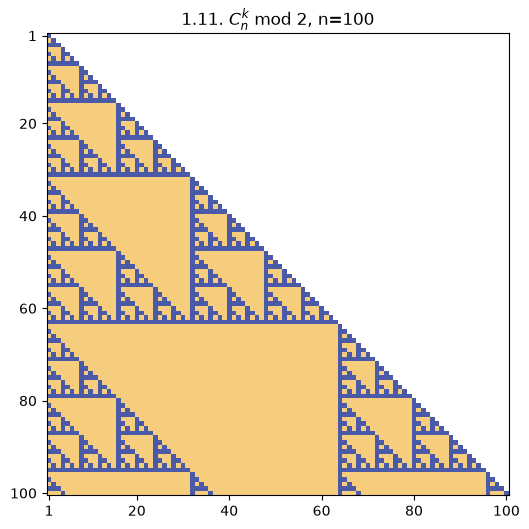

In [12]:
n_ = 100
B = np.full((n_,n_),np.nan)
for i in range(1,n_+1):
    for j in range(1,i+1):
        B[i-1,j-1] = comb(i,j)%2
assert np.array_equal(B[:3,:3][~np.isnan(B[:3,:3])],np.array([1,0,1,1,1,1]))  # пример n=3 из листка
fig,ax = plt.subplots(figsize=(6,6))
ax.imshow(B,cmap=ListedColormap(['#f6cd7c','#4a5aa8']),extent=[.5,n_+.5,n_+.5,.5])
ax.set_title('1.11. $C_n^k$ mod 2, n=100'); ax.set_xticks([1,20,40,60,80,100]); ax.set_yticks([1,20,40,60,80,100])
fig.savefig('fig/Sol_1_11.png',dpi=120,bbox_inches='tight'); plt.show()

**1.12.** Матрицы Адамара: $H_nH_n^T=nI_n$.

**а)** $H_1=(1)$, $H_2=\begin{pmatrix}1&1\\1&-1\end{pmatrix}$, $H_4=\begin{pmatrix}1&1&1&1\\1&-1&1&-1\\1&1&-1&-1\\1&-1&-1&1\end{pmatrix}$.

**б)** $H_2\otimes H_2=\begin{pmatrix}H_2&H_2\\H_2&-H_2\end{pmatrix}$, и это в точности $H_4$ (проверка ниже).

**в)\*** Докажем, что $H_2\otimes H_{2^{k-1}}$ — матрица Адамара порядка $2^k$. Её элементы равны $\pm1$. По свойствам $(A\otimes B)(C\otimes D)=AC\otimes BD$ и $(A\otimes B)^T=A^T\otimes B^T$ имеем
$$(H_2\otimes H_{2^{k-1}})(H_2\otimes H_{2^{k-1}})^T=H_2H_2^T\otimes H_{2^{k-1}}H_{2^{k-1}}^T=2I_2\otimes2^{k-1}I_{2^{k-1}}=2^kI_{2^k}.$$
Индукция по $k$ с базой $H_2$ даёт требуемое.

**г)** Матрица для $n=2^6$: оранжевый — $+1$, синий — $-1$. Как на рисунке в листке, строки упорядочены по числу смен знака.

[[ 1  1  1  1]
 [ 1 -1  1 -1]
 [ 1  1 -1 -1]
 [ 1 -1 -1  1]]


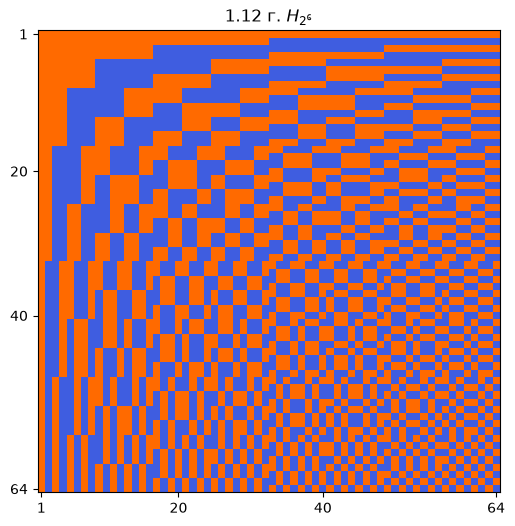

In [13]:
H2 = np.array([[1,1],[1,-1]])
H4 = np.kron(H2,H2); print(H4)
assert np.array_equal(H4@H4.T,4*np.eye(4,dtype=int))
H = np.array([[1]])
for k in range(6):
    H = np.kron(H2,H)
    assert np.array_equal(H@H.T,H.shape[0]*np.eye(H.shape[0],dtype=int))
by_changes = lambda M: M[np.argsort((np.diff(M,axis=1)!=0).sum(axis=1))]
assert np.array_equal(by_changes(H4),np.array([[1,1,1,1],[1,1,-1,-1],[1,-1,-1,1],[1,-1,1,-1]]))  # рисунок H4 из листка
fig,ax = plt.subplots(figsize=(6,6))
ax.imshow(by_changes(H),cmap=ListedColormap(['#3f5de0','#ff6a00']),extent=[.5,64.5,64.5,.5])
ax.set_title('1.12 г. $H_{2^6}$'); ax.set_xticks([1,20,40,64]); ax.set_yticks([1,20,40,64])
fig.savefig('fig/Sol_1_12.png',dpi=120,bbox_inches='tight'); plt.show()

**1.13.** Для $A=\begin{pmatrix}14&10&21\\12&15&26\\18&11&27\end{pmatrix}$ найти собственное значение $Z$ с наибольшей мнимой частью и собственный вектор $X=(1,U,V)$. Указать $\operatorname{Im}Z$ и $\operatorname{Re}U$.

In [14]:
A = np.array([[14.,10,21],[12,15,26],[18,11,27]])
w,v = np.linalg.eig(A)
i = np.argmax(w.imag); Z = w[i]; X = v[:,i]/v[0,i]
print('Z =',Z); print('X =',X)
assert np.allclose(A@X,Z*X)
print(f'Im Z = {Z.imag:.4f}, Re U = {X[1].real:.4f}')

Z = (1.9688403308016502+0.3447893484271669j)
X = [ 1.        -0.j          3.74781973+1.33084677j -2.35758843-0.61731802j]
Im Z = 0.3448, Re U = 3.7478


**1.14.** Найти минимальный многочлен матрицы $7\times7$ из листка.

Характеристический многочлен находим точно. Минимальный делит его и содержит те же корни, поэтому перебираем делители.

In [15]:
A = Matrix([[-3,7,-6,-1,8,-3,-2],[1,-5,8,-3,-5,4,-5],[1,3,-4,6,-2,0,8],[-1,11,-12,9,3,-3,9],
            [-3,11,-12,5,8,-4,6],[-3,2,1,-4,4,1,-7],[1,-5,6,-2,-4,3,-2]])
l = symbols('lambda')
display(sp.factor(A.charpoly(l).as_expr()))
I7 = sp.eye(7)
ok = [(a,b) for a in range(1,4) for b in range(1,5) if (A**a*(A-I7)**b).is_zero_matrix]
a,b = min(ok,key=sum); print('минимальные показатели:',a,b)
display(sp.expand(l**a*(l-1)**b))
assert (a,b)==(3,2)

минимальные показатели: 3 2


**Ответ:** $\mu(\lambda)=\lambda^3(\lambda-1)^2=\lambda^5-2\lambda^4+\lambda^3$.

**1.15.** Найти собственный ортонормированный базис и матрицу оператора в нём для $A=\begin{pmatrix}17&-8&4\\-8&17&-4\\4&-4&11\end{pmatrix}$.

In [16]:
A = Matrix([[17,-8,4],[-8,17,-4],[4,-4,11]])
basis=[]
for val,mult,vecs in A.eigenvects():
    basis += sp.GramSchmidt(vecs,True)
    print('lambda =',val,' кратность',mult)
P = Matrix.hstack(*basis); display(P)
assert sp.simplify(P.T*P)==sp.eye(3)
display(sp.simplify(P.T*A*P))

lambda = 9  кратность 2
lambda = 27  кратность 1


⎡√2  -√2       ⎤
⎢──  ────  2/3 ⎥
⎢2    6        ⎥
⎢              ⎥
⎢√2   √2       ⎥
⎢──   ──   -2/3⎥
⎢2    6        ⎥
⎢              ⎥
⎢    2⋅√2      ⎥
⎢0   ────  1/3 ⎥
⎣     3        ⎦

⎡9  0  0 ⎤
⎢        ⎥
⎢0  9  0 ⎥
⎢        ⎥
⎣0  0  27⎦

**Ответ:** собственные значения $9,9,27$; базис — столбцы матрицы выше; матрица оператора в нём $\operatorname{diag}(9,9,27)$.

**1.16.** Найти ортогональное преобразование к главным осям для $f=3x_1^2+8x_1x_2-3x_2^2+4x_3^2-4x_3x_4+x_4^2$.

Форма распадается на блоки по $(x_1,x_2)$ и $(x_3,x_4)$.

In [17]:
A = Matrix([[3,4,0,0],[4,-3,0,0],[0,0,4,-2],[0,0,-2,1]])
basis=[]; vals=[]
for val,mult,vecs in A.eigenvects():
    basis += sp.GramSchmidt(vecs,True); vals += [val]*mult
P = Matrix.hstack(*basis); display(P); print('собственные значения:',vals)
assert sp.simplify(P.T*P)==sp.eye(4) and sp.simplify(P.T*A*P)==sp.diag(*vals)
assert sorted(vals)==[-5,0,5,5]

⎡-√5         2⋅√5        ⎤
⎢────   0    ────    0   ⎥
⎢ 5           5          ⎥
⎢                        ⎥
⎢2⋅√5         √5         ⎥
⎢────   0     ──     0   ⎥
⎢ 5           5          ⎥
⎢                        ⎥
⎢       √5         -2⋅√5 ⎥
⎢ 0     ──    0    ──────⎥
⎢       5            5   ⎥
⎢                        ⎥
⎢      2⋅√5          √5  ⎥
⎢ 0    ────   0      ──  ⎥
⎣       5            5   ⎦

собственные значения: [-5, 0, 5, 5]


**Ответ:** преобразование $x=Py$ с матрицей $P$ выше приводит форму к главным осям, коэффициенты при $y_i^2$ равны напечатанным собственным значениям: $-5,0,5,5$. То есть $f=-5y_a^2+5y_b^2+5y_c^2$, а по одному из направлений форма равна нулю.

**1.17.** Определить тип кривой, каноническое уравнение и каноническую систему координат.

**a)** $5x^2+4xy+8y^2-32x-56y+80=0$. Матрица квадратичной части $\begin{pmatrix}5&2\\2&8\end{pmatrix}$, собственные значения $4$ и $9$ ($\det=36>0$, эллиптический тип). Центр находится из $10x+4y=32$, $4x+16y=56$: это $(2,3)$. Значение левой части в центре равно $-36$. В осях $e_1=\tfrac1{\sqrt5}(2,-1)$, $e_2=\tfrac1{\sqrt5}(1,2)$ с началом в центре получаем $4x'^2+9y'^2=36$:
$$\frac{x'^2}{9}+\frac{y'^2}{4}=1\quad\text{— эллипс}.$$

**b)** $5x^2+12xy-22x-12y-19=0$. Матрица $\begin{pmatrix}5&6\\6&0\end{pmatrix}$, собственные значения $9$ и $-4$ ($\det=-36<0$, гиперболический тип). Центр: $10x+12y=22$, $12x=12$, то есть $(1,1)$. Значение в центре равно $-36$. В осях $e_1=\tfrac1{\sqrt{13}}(3,2)$, $e_2=\tfrac1{\sqrt{13}}(2,-3)$ получаем $9x'^2-4y'^2=36$:
$$\frac{x'^2}{4}-\frac{y'^2}{9}=1\quad\text{— гипербола}.$$
Проверка подстановкой:

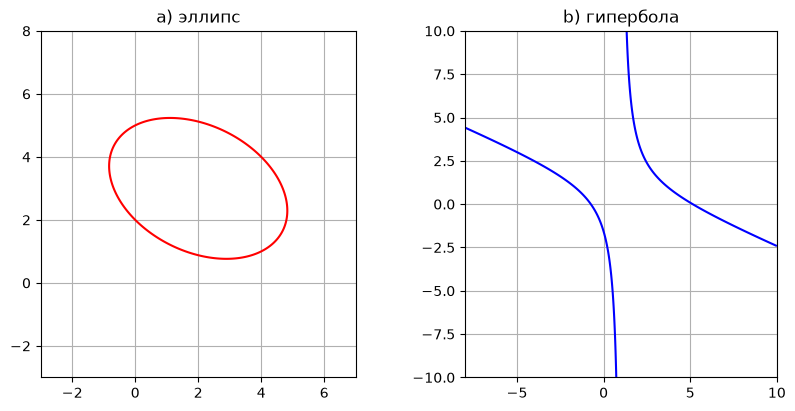

In [18]:
X,Y,xp,yp = symbols('x y xp yp')
def to_canon(F,cx,cy,e1,e2):
    return sp.expand(F.subs({X:cx+xp*e1[0]+yp*e2[0],Y:cy+xp*e1[1]+yp*e2[1]},simultaneous=True))
Fa = 5*X**2+4*X*Y+8*Y**2-32*X-56*Y+80
Fb = 5*X**2+12*X*Y-22*X-12*Y-19
s5,s13 = sqrt(5),sqrt(13)
ca = to_canon(Fa,2,3,(2/s5,-1/s5),(1/s5,2/s5)); cb = to_canon(Fb,1,1,(3/s13,2/s13),(2/s13,-3/s13))
display(ca,cb)
assert ca==4*xp**2+9*yp**2-36 and cb==9*xp**2-4*yp**2-36
fig,axs = plt.subplots(1,2,figsize=(10,4.5))
gx,gy = np.meshgrid(np.linspace(-3,7,600),np.linspace(-3,8,600))
axs[0].contour(gx,gy,sp.lambdify((X,Y),Fa)(gx,gy),[0],colors='r'); axs[0].set_title('a) эллипс')
gx,gy = np.meshgrid(np.linspace(-8,10,600),np.linspace(-10,10,600))
axs[1].contour(gx,gy,sp.lambdify((X,Y),Fb)(gx,gy),[0],colors='b'); axs[1].set_title('b) гипербола')
for a in axs: a.grid(True); a.set_aspect('equal')
fig.savefig('fig/Sol_1_17.png',dpi=120,bbox_inches='tight'); plt.show()

**1.18.** При каких $\lambda$ форма $Q=x_1^2+4x_2^2+x_3^2+2\lambda x_1x_2+10x_1x_3+6x_2x_3$ положительно определена?

Главный минор на переменных $x_1,x_3$ равен $\begin{vmatrix}1&5\\5&1\end{vmatrix}=-24<0$ при любом $\lambda$. Значит, форма не бывает положительно определённой: например, при $x=(1,0,-1)$ получаем $Q=1+1-10=-8<0$. То же показывает критерий Сильвестра: $\Delta_2=4-\lambda^2>0$ даёт $|\lambda|<2$, а $\Delta_3=-\lambda^2+30\lambda-105>0$ даёт $\lambda\in(15-2\sqrt{30},\,15+2\sqrt{30})\approx(4{,}05;\,25{,}95)$. Эти промежутки не пересекаются.

In [19]:
L = symbols('lambda',real=True)
A = Matrix([[1,L,5],[L,4,3],[5,3,1]])
d2,d3 = A[:2,:2].det(),A.det(); display(d2,d3)
s = sp.solve_univariate_inequality(d2>0,L,relational=False).intersect(sp.solve_univariate_inequality(d3>0,L,relational=False))
print('решение:',s); assert s==sp.EmptySet

решение: EmptySet


**Ответ:** таких $\lambda$ нет.

**1.19.** При каких $\lambda$ форма $Q=\lambda x_1^2-2x_2^2-3x_3^2+2x_1x_2-2x_1x_3+2x_2x_3$ отрицательно определена?

Критерий Сильвестра для отрицательной определённости: $\Delta_1<0,\ \Delta_2>0,\ \Delta_3<0$.

In [20]:
A = Matrix([[L,1,-1],[1,-2,1],[-1,1,-3]])
d1,d2,d3 = A[0,0],A[:2,:2].det(),A.det(); print(d1,'|',d2,'|',d3)
s = sp.Interval.open(-sp.oo,sp.oo)
for e in (d1<0,d2>0,d3<0):
    s = s.intersect(sp.solve_univariate_inequality(e,L,relational=False))
print('решение:',s); assert s==sp.Interval.open(-sp.oo,Rational(-3,5))

lambda | -2*lambda - 1 | 5*lambda + 3
решение: Interval.open(-oo, -3/5)


**Ответ:** $\lambda<-\tfrac35$.

**1.20.** Эквивалентны ли над $\mathbb R$ формы $Q_1=2x_1^2+9x_2^2+3x_3^2+8x_1x_2-4x_1x_3-10x_2x_3$ и $Q_2=2x_1^2+3x_2^2+6x_3^2-4x_1x_2-4x_1x_3+8x_2x_3$?

*В листке в $Q_2$ напечатано $2x_1$. Это опечатка: в квадратичной форме линейного слагаемого быть не может, поэтому считаем $2x_1^2$.*

По закону инерции формы эквивалентны над $\mathbb R$ тогда и только тогда, когда совпадают их сигнатуры. Выделим полные квадраты:
$$Q_1=2(x_1+2x_2-x_3)^2+(x_2-x_3)^2,\qquad Q_2=2(x_1-x_2-x_3)^2+(x_2+2x_3)^2.$$

In [21]:
A1 = Matrix([[2,4,-2],[4,9,-5],[-2,-5,3]]); A2 = Matrix([[2,-2,-2],[-2,3,4],[-2,4,6]])
def inertia(A):
    w = np.linalg.eigvalsh(np.array(A,float)); return int((w>1e-9).sum()),int((w<-1e-9).sum()),int((abs(w)<=1e-9).sum())
print('(+, -, 0):',inertia(A1),inertia(A2),' ранги',A1.rank(),A2.rank())
assert inertia(A1)==inertia(A2)
x1,x2,x3 = symbols('x1:4'); v = Matrix([x1,x2,x3])
assert sp.expand((v.T*A1*v)[0]-(2*(x1+2*x2-x3)**2+(x2-x3)**2))==0
assert sp.expand((v.T*A2*v)[0]-(2*(x1-x2-x3)**2+(x2+2*x3)**2))==0
print('разложения верны')

(+, -, 0): (2, 0, 1) (2, 0, 1)  ранги 2 2
разложения верны


**Ответ:** да, эквивалентны. Обе формы приводятся к $y_1^2+y_2^2$: сигнатура $(2,0)$, ранг $2$.